# AI251P — Football Project 6 | Phase 1 (Kaggle edition)

This copy adapts the **existing** Phase 1 notebook to Kaggle. Original saved outputs are historical and retained unchanged.


## Dataset and Kaggle workspace

Kaggle source data is read from `/kaggle/input` or extracted into `/kaggle/working`; new experiment artifacts are written to `/kaggle/working/football_project_outputs`.


## Kaggle runtime setup (new — original saved outputs preserved)

This copy uses the **same SoccerNet/SN-GSR-2025 source** as the earlier Colab notebook, but adapts its local paths to Kaggle. **Recommended:** in Kaggle, choose **Add Input → Dataset** and attach a dataset containing an extracted `Labels-GameState.json` directory tree, or a `train.zip` archive. The entire Hugging Face repository is ~35 GB; `train.zip` alone is ~9.76 GB and also needs extraction space. Internet must be enabled in Kaggle if downloading.

- Kaggle input files: `/kaggle/input` (read-only). New outputs: `/kaggle/working/football_project_outputs`.
- The following new cells have intentionally **no saved output**. Historical Phase 1 training results and figures are preserved in the original cells but were produced in another runtime; they **must not be interpreted as new Kaggle execution results**.
- **Executing all cells will train the models again**. To avoid retraining, skip the three training cells and later cells requiring their Python variables, or supply compatible checkpoints/artifacts and adapt the restore workflow. This conversion does not magically transfer local checkpoints to Kaggle.
- If several independent games are available, the Phase 1 match grouping uses those games; the archive's `train/valid/test` directories are not automatically treated as leak-safe matching groups.


In [1]:
# Kaggle: install small missing dependencies (torch/torchvision are preinstalled in most GPU images)
import sys, subprocess, importlib.util
required = {'huggingface_hub':'huggingface_hub', 'wandb':'wandb', 'datasets':'datasets'}
missing = [pip for module,pip in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('Kaggle setup: optional packages checked; missing installed:', missing)


Kaggle setup: optional packages checked; missing installed: []


In [2]:

# ============================================================
# SoccerNet GSR 2025 — Download from Hugging Face for Kaggle
# ============================================================

%pip install -q huggingface_hub hf_xet

from huggingface_hub import hf_hub_download
from pathlib import Path
import zipfile

REPO_ID = "SoccerNet/SN-GSR-2025"

DATA_DIR = Path("/kaggle/working/soccer_gsr")
EXTRACT_TO = DATA_DIR / "extracted"

DATA_DIR.mkdir(parents=True, exist_ok=True)
EXTRACT_TO.mkdir(parents=True, exist_ok=True)

# Check whether data is already extracted
label_files = list(EXTRACT_TO.rglob("Labels-GameState.json"))

if label_files:
    print("Dataset already extracted. Skipping download.")
else:
    print("Downloading SoccerNet train.zip from Hugging Face...")

    zip_path = hf_hub_download(
        repo_id=REPO_ID,
        filename="train.zip",
        repo_type="dataset",
        local_dir=str(DATA_DIR)
    )

    print("Download completed:", zip_path)

    print("Extracting dataset...")

    with zipfile.ZipFile(zip_path, "r") as zf:
        for member in zf.infolist():
            target = (EXTRACT_TO / member.filename).resolve()
            if not target.is_relative_to(EXTRACT_TO.resolve()):
                raise ValueError(f"Unsafe ZIP path: {member.filename}")
        zf.extractall(EXTRACT_TO)

    print("Extraction completed.")

# Define the dataset path for Phase 1
GSR_ROOT = EXTRACT_TO

# Verify annotations
label_files = sorted(GSR_ROOT.rglob("Labels-GameState.json"))

print("\nGSR_ROOT:", GSR_ROOT)
print("Total annotation files:", len(label_files))

if not label_files:
    raise FileNotFoundError(
        "No Labels-GameState.json files found after extraction."
    )

print("Example:", label_files[0])


Note: you may need to restart the kernel to use updated packages.


train.zip: reconstructing file:   0%|          |  0.00B / 9.76GB            

train.zip: downloading bytes:           |  0.00B            

Download completed: /kaggle/working/soccer_gsr/train.zip
Extracting dataset...
Extraction completed.

GSR_ROOT: /kaggle/working/soccer_gsr/extracted
Total annotation files: 57
Example: /kaggle/working/soccer_gsr/extracted/SNGS-060/Labels-GameState.json


In [ ]:
# [ADDED] Free disk space after extraction: delete train.zip (9.76 GB) and Hugging Face download caches
# (on Kaggle's ~20 GB disk the kept zip caused "No space left on device" while saving frames)
import shutil
for z in DATA_DIR.glob('*.zip'): z.unlink()
shutil.rmtree(DATA_DIR/'.cache',ignore_errors=True)
shutil.rmtree(Path.home()/'.cache'/'huggingface'/'xet',ignore_errors=True)
print(f"Free disk: {shutil.disk_usage(DATA_DIR).free/1e9:.1f} GB")


In [3]:
from pathlib import Path
import os, json, random, hashlib, shutil, sys, platform, time, gc, math, importlib.metadata
from collections import Counter, defaultdict
from datetime import datetime, timezone
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2
from PIL import Image, ImageOps, ImageDraw
from tqdm.auto import tqdm
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_fscore_support, accuracy_score, f1_score)
from sklearn.cluster import KMeans
from scipy.optimize import linear_sum_assignment
from scipy.stats import beta
import torch, torchvision, wandb
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
import yaml
print('Python:',sys.version.split()[0], '| torch:',torch.__version__, '| torchvision:',torchvision.__version__)

Python: 3.13.15 | torch: 2.11.0+cu128 | torchvision: 0.26.0+cu128


## Experiment configuration and reproducibility

A single configuration defines the random seed, image resolution (224 × 224 for role classification), temporal subsampling, match-level partitions, optimization settings, detection resolution (960), and acceptance criteria. The run directory contains the configuration, environment information, and available package versions. CUDA, Apple Silicon MPS, or CPU is selected from the active environment.


In [4]:
CFG = dict(
    gsr_root=str(GSR_ROOT), output_root='/kaggle/working/football_project_outputs',
    seed=42, image_size=224, frame_step=25, max_clips=48, max_frames_per_clip=35,
    max_crop_per_class=3500, min_crop_side=24, min_independent_matches=3,
    test_fraction=0.20, val_fraction=0.20, batch_size=32, num_workers=0,
    scratch_epochs=16, frozen_epochs=10, full_epochs=10, patience=4,
    scratch_lr=1e-3, frozen_lr=1e-3, full_lr=1e-4,
    weight_decay=1e-4, grad_clip=1.0, wandb_project='football-capstone-ai251p',
    wandb_mode='offline', prototype_train_per_class=90, prototype_val_per_class=90,
    detector_epochs=35, detector_imgsz=960, detector_batch=8,
    segmentation_epochs=12, segmentation_batch=4, segmentation_size=(512,288),
    audit_n=120, n_ball_review_frames=450,
    ball_min_conf=0.65, ball_min_area_ratio=0.000008, ball_max_area_ratio=0.004,
    ball_min_aspect=0.40, ball_max_aspect=2.5,
    # Preset BEFORE results; illustrative project acceptance criteria (adjust before experiments).
    min_role_macro_f1=0.75, min_ball_recall=0.70, min_pitch_mean_iou=0.55,
    max_p95_latency_ms=300, # device-specific target; clearly report backend
)
SEED=CFG['seed']
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
if torch.cuda.is_available():
    DEVICE=torch.device('cuda');torch.cuda.manual_seed_all(SEED)
elif getattr(torch.backends,'mps',None) and torch.backends.mps.is_available():
    DEVICE=torch.device('mps')
else: DEVICE=torch.device('cpu')
ROOT=Path(CFG['gsr_root'])
RUN_ID=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
OUT=Path(CFG['output_root'])/RUN_ID
CACHE=OUT/'data_cache'; REVIEW=OUT/'quality_checks'
for p in [OUT,CACHE,REVIEW]: p.mkdir(parents=True,exist_ok=True)
(OUT/'config.json').write_text(json.dumps(CFG,indent=2))
PACKAGES=['torch','torchvision','numpy','pandas','Pillow','opencv-python','scikit-learn','scipy',
          'matplotlib','wandb','ultralytics','segmentation-models-pytorch','onnx','onnxruntime','fastapi']
(OUT/'requirements-lock.txt').write_text('\n'.join(
    f'{p}=={importlib.metadata.version(p)}' for p in PACKAGES if importlib.metadata.packages_distributions() and
    (lambda a: a is not None)(importlib.util.find_spec({'Pillow':'PIL','opencv-python':'cv2','scikit-learn':'sklearn',
    'segmentation-models-pytorch':'segmentation_models_pytorch'}.get(p,p)))
)+'\n')
(OUT/'environment.json').write_text(json.dumps({'python':sys.version,'platform':platform.platform(),
                                               'device':str(DEVICE)},indent=2))
print('Device:', DEVICE, '| Dataset:',CFG['gsr_root'], '| Outputs:',CFG['output_root'])

Device: cuda | Dataset: /kaggle/working/soccer_gsr/extracted | Outputs: /kaggle/working/football_project_outputs


In [ ]:
# [ADDED] Reproducibility: make cuDNN deterministic so reruns with the same seed give the same numbers
# (also installs tabulate, used to write the Markdown tables of the dataset card and plan)
if importlib.util.find_spec('tabulate') is None: subprocess.check_call([sys.executable,'-m','pip','install','-q','tabulate'])
torch.backends.cudnn.deterministic=True
torch.backends.cudnn.benchmark=False
print('cuDNN deterministic:',torch.backends.cudnn.deterministic)


### M1 — Local annotation inventory

Identify available GSR annotation files and confirm their paths before extracting frames. The source annotation schema determines which labels are usable for each task.


In [5]:
from pathlib import Path
ROOT = Path(CFG['gsr_root'])
if not ROOT.is_dir():
    raise FileNotFoundError(f'Expected dataset folder: {ROOT}. Attach/extract SoccerNet GSR using the Kaggle setup cell.')
json_files = sorted(ROOT.rglob('Labels-GameState.json'))
print('Dataset root:', ROOT)
print('Found annotation files:', len(json_files))
print('Sequence examples:', [str(p.parent.relative_to(ROOT)) for p in json_files[:8]])
if not json_files:
    raise FileNotFoundError('No Labels-GameState.json found. Attach/extract the GSR dataset using the Kaggle setup cell.')

Dataset root: /kaggle/working/soccer_gsr/extracted
Found annotation files: 57
Sequence examples: ['SNGS-060', 'SNGS-061', 'SNGS-062', 'SNGS-063', 'SNGS-064', 'SNGS-065', 'SNGS-066', 'SNGS-067']


### M1 — Visual inspection of source annotations

Representative frames are displayed with available annotated objects to establish the original image dimensions, object scales, and annotation coverage. This provides context for subsequent geometric filtering and crop extraction.


Source: SNGS-060/Labels-GameState.json
Keys: ['info', 'images', 'annotations', 'categories']
Info: {
  "version": "1.3",
  "game_id": "4",
  "id": "060",
  "num_tracklets": "26",
  "action_position": "895",
  "action_class": "Kick-off",
  "visibility": "visible",
  "game_time_start": "1 - 00:00",
  "game_time_stop": "1 - 00:30",
  "clip_start": "0",
  "clip_stop": "30000",
  "name": "SNGS-060",
  "im_dir": "img1",
  "frame_rate": 25,
  "seq_length": 750,
  "im_ext": ".jpg"
}
Frames: 750 Objects: 14290
Sample image record: {"is_labeled": true, "image_id": "1060000001", "file_name": "000001.jpg", "height": 1080, "width": 1920, "has_labeled_person": true, "has_labeled_pitch": true, "has_labeled_camera": true, "ignore_regions_y": [], "ignore_regions_x": []}
Sample object: {"id": "1060000001", "image_id": "1060000001", "track_id": 1, "supercategory": "object", "category_id": 1, "attributes": {"role": "player", "jersey": "10", "team": "left"}, "bbox_image": {"x": 914, "y": 855, "x_center": 9

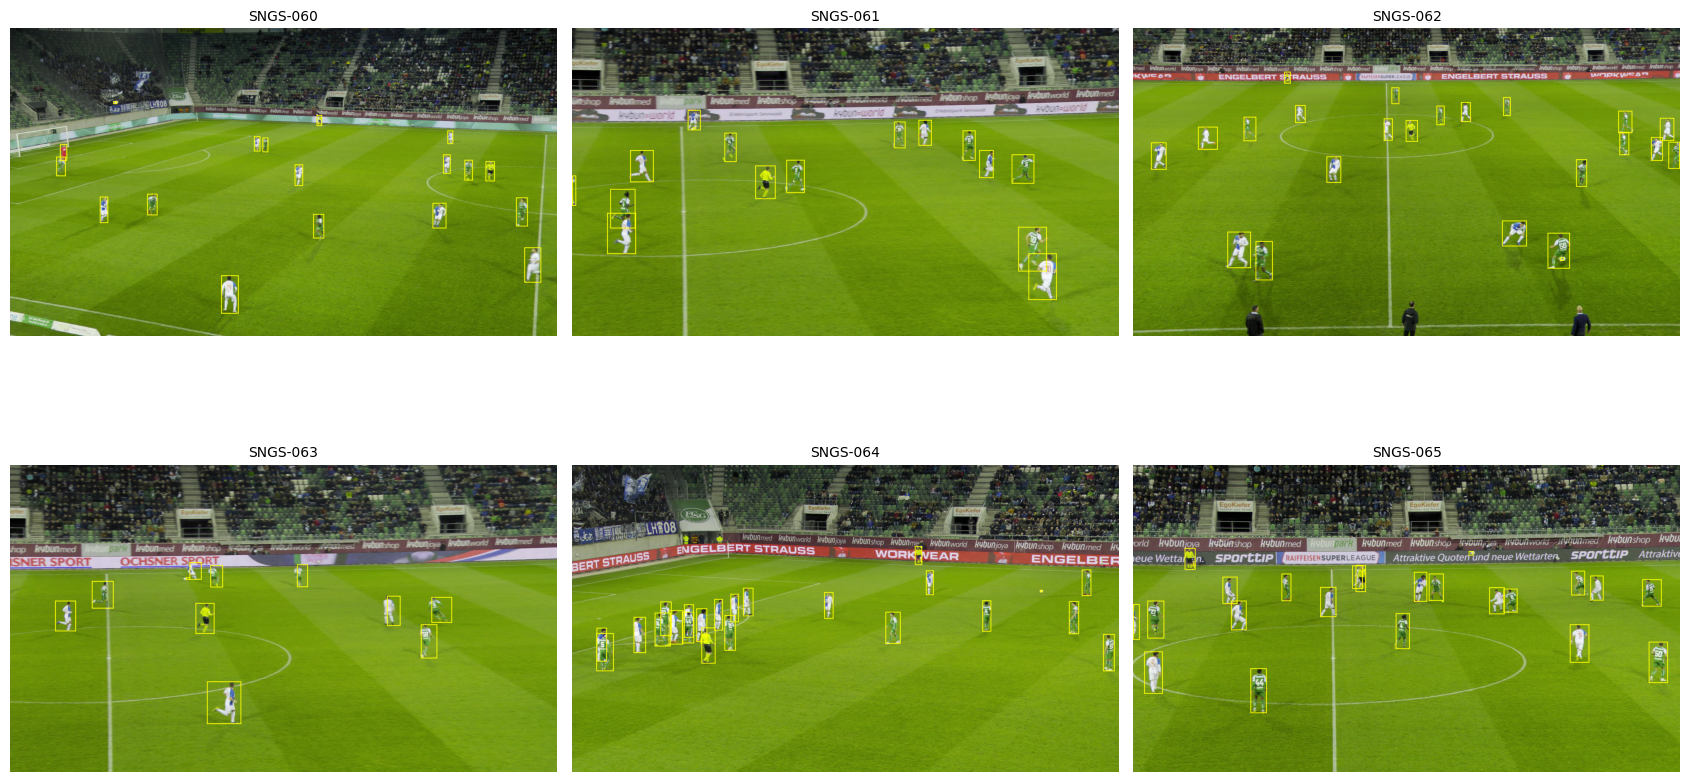

Displayed 6 frames from different sequences.


In [6]:
from PIL import Image, ImageOps, ImageDraw
from IPython.display import display
import matplotlib.pyplot as plt
from collections import defaultdict
import json, cv2

sample_path = json_files[0]
with sample_path.open(encoding='utf-8') as handle:
    sample_doc = json.load(handle)
print('Source:', sample_path.relative_to(ROOT))
print('Keys:', list(sample_doc))
print('Info:', json.dumps(sample_doc.get('info', {}), ensure_ascii=False, indent=2)[:1400])
print('Frames:', len(sample_doc.get('images', [])), 'Objects:', len(sample_doc.get('annotations', [])))
print('Sample image record:', json.dumps(sample_doc.get('images', [None])[0], ensure_ascii=False)[:1000])
print('Sample object:', json.dumps(sample_doc.get('annotations', [None])[0], ensure_ascii=False)[:1200])

def preview_image(seq_dir, info, rec, ordinal):
    name = str(rec.get('file_name', ''))
    for path in (seq_dir/name, seq_dir/str(info.get('im_dir') or 'img1')/name, seq_dir/'img1'/name):
        if path.is_file():
            with Image.open(path) as im:
                return ImageOps.exif_transpose(im).convert('RGB').copy()
    videos = sorted([*seq_dir.glob('*.mp4'), *seq_dir.glob('*.mkv')])
    if videos:
        capture = cv2.VideoCapture(str(videos[0]))
        frame_no = rec.get('frame_id')
        if frame_no is None:
            frame_no = ordinal + 1
        try:
            capture.set(cv2.CAP_PROP_POS_FRAMES, max(0, int(frame_no)-1))
            ok, bgr = capture.read()
        finally:
            capture.release()
        if ok:
            return Image.fromarray(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    return None

fig, axs = plt.subplots(2, 3, figsize=(17, 10))
shown = 0
for source in json_files:
    if shown >= 6: break
    with source.open(encoding='utf-8') as f: doc = json.load(f)
    records = doc.get('images', [])
    if not records: continue
    ann_index = defaultdict(list)
    for ann in doc.get('annotations', []): ann_index[str(ann.get('image_id'))].append(ann)
    ordinal = min(len(records)-1, max(0, len(records)//3))
    record = records[ordinal]
    rgb = preview_image(source.parent, doc.get('info', {}), record, ordinal)
    if rgb is None: continue
    drawer = ImageDraw.Draw(rgb)
    for ann in ann_index.get(str(record.get('id', record.get('image_id'))), []):
        bbox = ann.get('bbox_image') or {}
        if isinstance(bbox, dict) and all(k in bbox for k in ('x', 'y', 'w', 'h')):
            x, y, w, h = (float(bbox[k]) for k in ('x','y','w','h'))
            drawer.rectangle((x, y, x+w, y+h), outline='yellow', width=3)
    ax = axs.flat[shown]
    ax.imshow(rgb)
    ax.set_title(str(source.parent.relative_to(ROOT)), fontsize=10)
    ax.axis('off')
    shown += 1
for ax in list(axs.flat)[shown:]: ax.axis('off')
plt.tight_layout()
plt.show()
print(f'Displayed {shown} frames from different sequences.')
if not shown: print('No frame image or video could be decoded; inspect the local sequence structure.')

## M1 — Data foundations: source schema

Parse the GSR sequence metadata and inspect `Labels-GameState.json`. Source match identifiers are essential because adjacent clips and frames from the same game must not cross the train, validation, and test boundaries.


In [7]:
json_files = sorted(ROOT.rglob('Labels-GameState.json'))
if not json_files:
    raise FileNotFoundError('No Labels-GameState.json under configured Kaggle GSR_ROOT')
print('Number of sequences:',len(json_files))
print('First source:',json_files[0].relative_to(ROOT))
with json_files[0].open(encoding='utf-8') as f: sample=json.load(f)
print('Top-level:',list(sample))
print('Info fields:', sample.get('info',{}))
print('First image:',sample.get('images',[None])[0])
print('First annotation:',sample.get('annotations',[None])[0])
assert {'images','annotations'}.issubset(sample), 'Unexpected JSON schema; inspect source before proceeding.'

Number of sequences: 57
First source: SNGS-060/Labels-GameState.json
Top-level: ['info', 'images', 'annotations', 'categories']
Info fields: {'version': '1.3', 'game_id': '4', 'id': '060', 'num_tracklets': '26', 'action_position': '895', 'action_class': 'Kick-off', 'visibility': 'visible', 'game_time_start': '1 - 00:00', 'game_time_stop': '1 - 00:30', 'clip_start': '0', 'clip_stop': '30000', 'name': 'SNGS-060', 'im_dir': 'img1', 'frame_rate': 25, 'seq_length': 750, 'im_ext': '.jpg'}
First image: {'is_labeled': True, 'image_id': '1060000001', 'file_name': '000001.jpg', 'height': 1080, 'width': 1920, 'has_labeled_person': True, 'has_labeled_pitch': True, 'has_labeled_camera': True, 'ignore_regions_y': [], 'ignore_regions_x': []}
First annotation: {'id': '1060000001', 'image_id': '1060000001', 'track_id': 1, 'supercategory': 'object', 'category_id': 1, 'attributes': {'role': 'player', 'jersey': '10', 'team': 'left'}, 'bbox_image': {'x': 914, 'y': 855, 'x_center': 941.5, 'y_center': 941.0,

### M1 — Frame sampling and person-box extraction

Frames are subsampled at a stride of 25 to reduce temporal redundancy. The parser extracts source-aligned person bounding boxes and role labels (`player`, `goalkeeper`, `referee`), retaining links to frame and match identifiers. Ball and pitch annotations are handled separately in M4 and M5.


In [8]:
ROLE_NAMES=['player','goalkeeper','referee']
ROLE_TO_ID={v:i for i,v in enumerate(ROLE_NAMES)}
DET_NAMES=['player','goalkeeper','referee','ball']

def clean_role(role):
    value=str(role or '').lower().strip()
    if 'referee' in value: return 'referee'
    if 'goalkeeper' in value: return 'goalkeeper'
    if value=='player': return 'player'
    return None

def safe_id(s):
    return ''.join(c if c.isalnum() or c in ('-','_') else '_' for c in str(s))

def video_for_seq(seq_dir):
    options=sorted(list(seq_dir.glob('*.mp4'))+list(seq_dir.glob('*.mkv')))
    return options[0] if options else None

def load_frame(seq_dir, info, image_record, ordinal, cap=None):
    name=str(image_record.get('file_name',''))
    paths=[seq_dir/name,seq_dir/str(info.get('im_dir') or 'img1')/name,seq_dir/'img1'/name]
    for p in paths:
        if p.is_file():
            with Image.open(p) as im: return ImageOps.exif_transpose(im).convert('RGB').copy()
    if cap is None: raise FileNotFoundError('No frame image or MP4 found for '+str(seq_dir))
    # GSR frame order is the authoritative index. Confirm alignment in visual audit below.
    cap.set(cv2.CAP_PROP_POS_FRAMES,max(0,int(image_record.get('frame_id') or ordinal+1)-1))
    ok,bgr=cap.read()
    if not ok: raise IOError(f'Could not decode ordinal frame {ordinal} in {seq_dir}')
    return Image.fromarray(cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB))

frames, boxes, errors, clip_metadata=[],[],[],[]
for source in tqdm(json_files[:CFG['max_clips']],desc='Extract annotated frames'):
    with source.open() as f: doc=json.load(f)
    info=doc.get('info',{})
    match_id = info.get('game_id') or info.get('match_id')
    # DO NOT assume one sequence equals one independent game.
    # For missing IDs, create a placeholder that MUST be verified before splitting.
    if match_id is None or not str(match_id).strip():
        match_id = 'UNVERIFIED__' + source.parent.name
    clip_id=str(info.get('name') or source.parent.name)
    seq_name=safe_id(source.parent.name+'_'+clip_id)+'_'+hashlib.sha1(str(source).encode()).hexdigest()[:8]
    ims=doc.get('images',[])
    if not ims: continue
    ann_by_image=defaultdict(list)
    for a in doc.get('annotations',[]):
        ann_by_image[str(a.get('image_id'))].append(a)
    vid=video_for_seq(source.parent)
    cap=cv2.VideoCapture(str(vid)) if vid else None
    clip_metadata.append({'clip_id':clip_id,'source':str(source),'match_id':str(match_id), 'match_id_from_source':not str(match_id).startswith('UNVERIFIED__'),
                          'video':str(vid) if vid else '', 'n_images':len(ims)})
    count=0
    try:
        for ordinal in range(0,len(ims),int(CFG['frame_step'])):
            if count>=CFG['max_frames_per_clip']: break
            img_rec=ims[ordinal]
            if not img_rec.get('is_labeled',True): continue
            try: im=load_frame(source.parent,info,img_rec,ordinal,cap)
            except Exception as e:
                errors.append({'source':str(source.relative_to(ROOT)),'ordinal':ordinal,'error':str(e)});continue
            w,h=im.size
            frame_id=f'{seq_name}_{safe_id(img_rec.get("image_id",ordinal))}'
            frame_path=CACHE/'frames'/seq_name/f'{frame_id}.jpg'
            frame_path.parent.mkdir(parents=True,exist_ok=True)
            im.save(frame_path,quality=93)
            frames.append({'frame_id':frame_id,'path':str(frame_path), 'match_id':str(match_id),
                           'clip_id':seq_name, 'ordinal':ordinal, 'width':w,'height':h,
                           'source_json':str(source),'image_id':str(img_rec.get('id', img_rec.get('image_id', ordinal)))})
            for a in ann_by_image.get(str(img_rec.get('id', img_rec.get('image_id', ordinal))),[]):
                attrs=a.get('attributes') or {}
                role=clean_role(attrs.get('role'))
                bb=a.get('bbox_image') or {}
                if role is None or not {'x','y','w','h'}<=bb.keys():continue
                try:
                    x1=max(0,int(round(float(bb['x'])))); y1=max(0,int(round(float(bb['y']))))
                    x2=min(w,int(round(float(bb['x'])+float(bb['w']))))
                    y2=min(h,int(round(float(bb['y'])+float(bb['h']))))
                except (ValueError,TypeError):continue
                if x2<=x1 or y2<=y1:continue
                boxes.append({'frame_id':frame_id,'match_id':str(match_id),'role':role,
                              'team':str(attrs.get('team') or '').lower(),
                              'x1':x1,'y1':y1,'x2':x2,'y2':y2})
            count+=1
    finally:
        if cap is not None: cap.release()

frames=pd.DataFrame(frames); boxes=pd.DataFrame(boxes); clips=pd.DataFrame(clip_metadata)
if frames.empty or boxes.empty:raise ValueError('No labeled people/frames found; inspect dataset structure and decoding issues.')
if frames.frame_id.duplicated().any(): raise ValueError('Frame IDs collide; adjust safe sequence IDs.')
frames.to_csv(OUT/'frame_manifest.csv',index=False)
boxes.to_csv(OUT/'person_boxes.csv',index=False)
clips.to_csv(OUT/'source_clips.csv',index=False)
pd.DataFrame(errors,columns=['source','ordinal','error']).to_csv(OUT/'frame_decode_errors.csv',index=False)
print('Frames:',len(frames),'| person boxes:',len(boxes),'| independent matches:',frames.match_id.nunique())
display(boxes.role.value_counts().rename('Annotated people'))
if not clips.match_id_from_source.all():
    print('WARNING: Some match IDs are missing. Fill source_and_box_review.csv with verified match IDs BEFORE split.')
if frames.match_id.nunique()<CFG['min_independent_matches'] and clips.match_id_from_source.all():
    raise ValueError('Insufficient independent match IDs. Increase data, rather than splitting clips from a single match.')

Extract annotated frames:   0%|          | 0/48 [00:00<?, ?it/s]

OSError: [Errno 28] No space left on device

### M1 — Geometry inspection

Visualize sampled frames and bounding boxes. The automated cleaning stage checks that coordinates form nonempty rectangles inside the corresponding image; geometrically invalid annotations are excluded from the derived dataset.


In [ ]:
fig,axes=plt.subplots(2,3,figsize=(15,8));rng=np.random.default_rng(SEED)
for ax,ix in zip(axes.flat,rng.choice(len(frames),size=min(6,len(frames)),replace=False)):
    record=frames.iloc[ix]
    with Image.open(record.path) as im: rgb=im.convert('RGB').copy()
    dr=ImageDraw.Draw(rgb)
    for b in boxes[boxes.frame_id==record.frame_id].itertuples():
        dr.rectangle((b.x1,b.y1,b.x2,b.y2),outline={'player':'yellow','goalkeeper':'cyan','referee':'red'}[b.role],width=3)
    ax.imshow(rgb);ax.set_title(f'match={record.match_id}, frame={record.ordinal}',fontsize=9);ax.axis('off')
for ax in axes.flat:
    if not ax.images: ax.axis('off')
plt.tight_layout();plt.savefig(OUT/'bbox_alignment_review.png',dpi=120);plt.show()
print('Bounding-box overview saved: ', OUT/'bbox_alignment_review.png')


### M1 — Leakage-safe partitioning by match

Frames from the same match share camera position, jerseys, and temporal context. Splitting individual frames would therefore inflate evaluation results. The implementation assigns **entire source-identified matches** to train, validation, or test. When the subset contains exactly three matches, each partition receives one match; the resulting proportions need not equal 60/20/20 by frame count.

Automated preprocessing excludes annotations with invalid geometry and frames without retained person boxes. The split table documents label balance and match provenance.


In [ ]:
# Automated M1 source/box audit (no user-edited CSV)
source_ok = clips['match_id_from_source'].fillna(False).astype(bool)
invalid_sources = set(clips.loc[~source_ok,'source'].astype(str))
if invalid_sources:
    print('Excluding sequences missing source-provided match identity:',len(invalid_sources))
    frames=frames[~frames.source_json.isin(invalid_sources)].copy()
valid_ids=set(frames.frame_id)
boxes=boxes[boxes.frame_id.isin(valid_ids)].copy()
geom=(boxes.x1>=0)&(boxes.y1>=0)&(boxes.x2>boxes.x1)&(boxes.y2>boxes.y1)
frame_dimensions=frames.set_index('frame_id')[['width','height']]
joined=boxes.join(frame_dimensions,on='frame_id',how='left')
geom &= (joined.x2<=joined.width)&(joined.y2<=joined.height)
dropped=int((~geom).sum());boxes=boxes.loc[geom].copy()
# Exclude images without retained people boxes, rather than inventing labels
kept=set(boxes.frame_id)
removed_empty=int((~frames.frame_id.isin(kept)).sum())
frames=frames[frames.frame_id.isin(kept)].copy()
pd.DataFrame([{'stage':'M1','rejected_invalid_boxes':dropped,'rejected_no_boxes_frames':removed_empty,
               'excluded_unknown_match_sources':len(invalid_sources)}]).to_csv(OUT/'automatic_m1_cleaning.csv',index=False)
print('Automatic cleaning: invalid boxes',dropped,'| empty frames removed',removed_empty)


In [ ]:
# Strict group-by-match split. No manual review gates; preserve provenance warning.
match_values=np.array(sorted(frames.match_id.astype(str).unique()))
if len(match_values)<3:raise RuntimeError('Need at least 3 source-identified matches for train/val/test.')
if len(match_values)<CFG['min_independent_matches']:
    print('WARNING: Fewer groups than configured. Dataset needs more independent matches.')
# With three groups, one match goes to each partition; for more, group shuffle.
if len(match_values)==3:
    rng=np.random.default_rng(SEED); shuffled=rng.permutation(match_values)
    assigned={str(shuffled[0]):'train',str(shuffled[1]):'val',str(shuffled[2]):'test'}
else:
    outer=GroupShuffleSplit(n_splits=1,test_size=CFG['test_fraction'],random_state=SEED)
    i,j=next(outer.split(match_values,groups=match_values))
    trainval_matches=match_values[i]; test_matches=match_values[j]
    inner=GroupShuffleSplit(n_splits=1,test_size=CFG['val_fraction']/(1-CFG['test_fraction']),random_state=SEED+1)
    a,b=next(inner.split(trainval_matches,groups=trainval_matches))
    assigned={str(m):'train' for m in trainval_matches[a]}
    assigned.update({str(m):'val' for m in trainval_matches[b]})
    assigned.update({str(m):'test' for m in test_matches})
frames['match_id']=frames.match_id.astype(str)
frames['split']=frames.match_id.map(assigned)
boxes=boxes.drop(columns=['match_id','split','path'],errors='ignore').merge(
    frames[['frame_id','split','path','match_id']],on='frame_id',how='inner',validate='many_to_one')
assert frames.groupby('match_id').split.nunique().max()==1
assert set(frames.split)=={'train','val','test'}
frames.to_csv(OUT/'frame_manifest.csv',index=False);boxes.to_csv(OUT/'person_boxes.csv',index=False)
print('Automated match-level split (source-provided IDs):');display(pd.crosstab(frames.split,frames.match_id))
display(pd.crosstab(boxes.split,boxes.role))


In [ ]:
# [ADDED] M1 ball vs people imbalance: count ball boxes on the same sampled frames, per split
ball_rows=[]
for source,g in frames.groupby('source_json'):
    with open(source,encoding='utf-8') as f: doc=json.load(f)
    cat=[c.get('id') for c in doc.get('categories',[]) if str(c.get('name','')).lower()=='ball']
    is_ball=lambda a:str((a.get('attributes') or {}).get('role') or '').lower()=='ball' or a.get('category_id') in cat
    per_image=Counter(str(a.get('image_id')) for a in doc.get('annotations',[]) if is_ball(a))
    for r in g.itertuples(): ball_rows.append({'frame_id':r.frame_id,'split':r.split,'balls':per_image.get(str(r.image_id),0)})
balls=pd.DataFrame(ball_rows)
imbalance=pd.crosstab(boxes.split,boxes.role).reindex(columns=ROLE_NAMES,fill_value=0)
imbalance['ball']=balls.groupby('split').balls.sum().reindex(imbalance.index).fillna(0).astype(int)
imbalance['people_per_ball']=(imbalance[ROLE_NAMES].sum(1)/imbalance['ball'].replace(0,np.nan)).round(1)
imbalance['frames_with_ball_%']=(balls.assign(has=balls.balls>0).groupby('split').has.mean()*100).reindex(imbalance.index).round(1)
imbalance=imbalance.reindex(['train','val','test'])
imbalance.to_csv(OUT/'ball_vs_people_imbalance.csv');display(imbalance)
print('Matches per split:',frames.groupby('split').match_id.nunique().to_dict())


### M1 — Player-role crops, deduplication, and class audit

Extract classification crops from valid person boxes, reject unusably small crops, and control duplicate content. The three classification targets are **player, goalkeeper, and referee**. Class frequencies are reported by split; team appearance is examined in a separate analysis.


In [ ]:
records=[];seen={} ;invalid=[]
# Process minority roles too; deterministic order then limit each class globally to manageable subset.
for b in tqdm(boxes.itertuples(index=False),total=len(boxes),desc='Save role crops'):
    if min(b.x2-b.x1,b.y2-b.y1)<CFG['min_crop_side']:
        invalid.append({'frame_id':b.frame_id,'reason':'tiny role crop'});continue
    with Image.open(b.path) as im: crop=im.convert('RGB').crop((b.x1,b.y1,b.x2,b.y2))
    digest=hashlib.sha256(np.array(crop.resize((48,48))).tobytes()).hexdigest()
    if digest in seen:
        old_match,old_role=seen[digest]
        if old_match!=b.match_id:
            raise ValueError(f'Exact near-normalized duplicate crop across MATCHES: {old_match} vs {b.match_id}; review match grouping or duplicate provenance BEFORE splitting.')
        if old_role!=b.role:
            invalid.append({'frame_id':b.frame_id,'reason':'duplicate image with conflicting role'})
        continue
    seen[digest]=(b.match_id,b.role)
    ix=len(records)
    target=CACHE/'role_crops'/b.role/f'{safe_id(b.frame_id)}_{ix}.jpg'
    target.parent.mkdir(parents=True,exist_ok=True);crop.save(target,quality=94)
    records.append({'path':str(target),'role':b.role,'label':ROLE_TO_ID[b.role],
                    'split':b.split,'match_id':b.match_id,'frame_id':b.frame_id,'sha256':digest})
crops=pd.DataFrame(records)
# Sample TRAIN only, to keep an efficient project subset without discarding held-out evaluation.
rng=np.random.default_rng(SEED)
keep=[]
for (split,role),g in crops.groupby(['split','role']):
    cap=CFG['max_crop_per_class'] if split=='train' else max(200,CFG['max_crop_per_class']//4)
    keep.extend(g.sample(n=min(cap,len(g)),random_state=SEED).index.tolist())
crops=crops.loc[sorted(keep)].reset_index(drop=True)
crops.to_csv(OUT/'role_manifest.csv',index=False)
pd.DataFrame(invalid).to_csv(OUT/'invalid_role_crops.csv',index=False)
class_balance=pd.crosstab(crops.split,crops.role).reindex(index=['train','val','test'],columns=ROLE_NAMES,fill_value=0)
display(class_balance)
if (class_balance==0).any().any():
    raise ValueError('At least one split lacks one of the roles; add games or choose a documented role scheme. Do NOT mix match groups.')
print('Role crop count:',len(crops),'| filtered:',len(invalid))

### M1 — Annotation-consistency audit

Summarize retained crops, class counts, and match coverage after automated filtering. These checks identify missing fields, impossible boxes, and repeated images; they do **not** independently establish the correctness of every semantic role label.


In [ ]:
# Automated crop label consistency checks; no human validation fields.
audit_report=crops.groupby(['split','role']).agg(count=('path','size'),unique_matches=('match_id','nunique')).reset_index()
audit_report.to_csv(OUT/'automatic_crop_audit.csv',index=False)
display(audit_report)
print('Semantic label-error upper bound: NOT MEASURABLE without an independently labeled audit.')


In [ ]:
# [ADDED] M1 audit report: one table with the count of every cleaning step and a leakage check
tiny=sum(r['reason']=='tiny role crop' for r in invalid)
leak=crops.groupby('match_id').split.nunique().max()
audit_table=pd.DataFrame([
    ('unreadable / corrupt frames',len(errors)),
    ('invalid boxes removed',dropped),
    ('frames with no person removed',removed_empty),
    ('crops smaller than min_crop_side',tiny),
    ('exact duplicate crops removed',len(boxes)-tiny-len(records)),
    ('duplicates with conflicting role',sum(r['reason']=='duplicate image with conflicting role' for r in invalid)),
    ('matches appearing in more than one split',int(leak>1))],columns=['check','count'])
audit_table.to_csv(OUT/'audit_report.csv',index=False);display(audit_table)


In [ ]:
# [ADDED] M1 label audit, part 1: show 200 random crops with their labels (index: role) for manual review
LABEL_AUDIT_N=200
audit_sample=crops.sample(n=min(LABEL_AUDIT_N,len(crops)),random_state=SEED).reset_index(drop=True)
audit_sample.to_csv(OUT/'label_audit_sample.csv',index_label='audit_index')
for start in range(0,len(audit_sample),50):
    page=audit_sample.iloc[start:start+50]
    fig,axes=plt.subplots(5,10,figsize=(20,12))
    for ax in axes.flat: ax.axis('off')
    for ax,(i,r) in zip(axes.flat,page.iterrows()):
        with Image.open(r.path) as im: ax.imshow(im)
        ax.set_title(f'{i}: {r.role}',fontsize=8)
    plt.suptitle(f'Label audit crops {start}-{start+len(page)-1}');plt.tight_layout();plt.show()


In [ ]:
# [ADDED] M1 label audit, part 2: index numbers of crops whose role label is WRONG (e.g. [12, 87]; [] if none).
# None = not reviewed yet. The upper bound is the one-sided 95% Clopper-Pearson bound on the label-error rate.
AUDIT_WRONG_IDS=None
label_audit=None
if AUDIT_WRONG_IDS is None:
    print('Label audit not reviewed yet (AUDIT_WRONG_IDS is None).')
else:
    n=len(audit_sample);k=len(set(AUDIT_WRONG_IDS))
    upper=float(beta.ppf(0.95,k+1,n-k)) if k<n else 1.0
    label_audit={'n_reviewed':n,'n_wrong':k,'observed_error_rate':k/n,'upper_bound_95':upper,'wrong_ids':sorted(set(AUDIT_WRONG_IDS))}
    (OUT/'label_audit.json').write_text(json.dumps(label_audit,indent=2))
    print(f'Label audit: {k}/{n} wrong -> error rate {k/n:.2%}, 95% upper bound {upper:.2%}')


### M1 — Dataset card and limitations

Record source identity, sampled sequences and matches, extraction rules, split policy, class balance, and known limitations. Important limitations include different match appearances, small/occluded objects, and uncertainty in automatically generated labels. Dataset licence and consent fields remain explicitly unverified unless independently documented.


In [ ]:
card_path=REVIEW/'dataset_card.json'
if not card_path.exists():
    card=dict(title='Football SoccerNet GSR local project subset',sources=['SoccerNet/SN-GSR-2025',
        'SoccerNet/SN-Tracking-2023 (metadata review only; MOT class IDs absent)'],
        schema='GSR object bbox_image and role/team attributes; optional manually validated ball boxes/pitch masks',
        selected_clips=len(clips),matches=int(frames.match_id.nunique()),sampled_frames=len(frames),
        crops=len(crops),labels=ROLE_NAMES,split='GroupShuffleSplit by source info.game_id',
        sampling=f'Every {CFG["frame_step"]} source frames, max {CFG["max_frames_per_clip"]} per clip',
        license_verified=False,license_evidence='TODO: direct dataset card + media rights',
        anonymization_and_consent='TODO: review faces/identifiers and redistribution',
        match_group_verified=False,known_weaknesses='Domain shift, ball imbalance, occlusion, broadcast shots')
    card_path.write_text(json.dumps(card,indent=2))
print('Dataset card:',card_path)

In [ ]:
# [ADDED] M1 dataset card written as Markdown from the measured numbers (licence facts from the course guidelines)
bal=pd.crosstab(crops.split,crops.role).reindex(index=['train','val','test'],columns=ROLE_NAMES,fill_value=0)
audit_line=('not reviewed yet' if label_audit is None else
            f"{label_audit['n_wrong']}/{label_audit['n_reviewed']} wrong labels in a random sample; "
            f"observed {label_audit['observed_error_rate']:.2%}, one-sided 95% upper bound {label_audit['upper_bound_95']:.2%}")
card_md=f'''# Dataset card: SoccerNet GSR-2025 role crops (Project 6, Phase 1)

## Source and licence
- SoccerNet Game State Reconstruction 2025, train split (https://huggingface.co/datasets/SoccerNet/SN-GSR-2025). Licence: GPL-3.0 (dataset card).
- These 30-second clips do not require the SoccerNet NDA (it applies only to full broadcast videos). Challenge-split labels are private and not used.
- Data are not committed to the repository and are not redistributed.

## Content used
- Clips: {len(clips)} | independent matches (info.game_id): {frames.match_id.nunique()} | sampled frames: {len(frames)}
- Sampling: 1 frame every {CFG["frame_step"]} frames, at most {CFG["max_frames_per_clip"]} per clip, because consecutive frames are nearly identical.
- Task: role classification of person crops ({", ".join(ROLE_NAMES)}) at {CFG["image_size"]}x{CFG["image_size"]} px.

## Split (leakage-safe)
- Whole matches go to train / val / test (GroupShuffleSplit on game_id, seed {SEED}); no match appears in two splits.
- Matches per split: {frames.groupby("split").match_id.nunique().to_dict()}

## Class balance per split (crops)
{bal.to_markdown()}

## Ball versus people
{imbalance.to_markdown()}

## Cleaning and audit
{audit_table.to_markdown(index=False)}

- Label audit: {audit_line}

## Privacy
Players and referees appear in published broadcast footage covered by the dataset licence; no images are redistributed and no identity is inferred.

## Limitations
- Few independent matches; the test split may hold a single match, so confidence intervals are wide and generalization claims are limited.
- Goalkeepers and referees are rare compared with players.
- The ball is tiny and present in only part of the frames (table above).
- Broadcast camera only: close-ups, shot changes, motion blur and occlusion; other leagues, kits and stadiums are out of distribution.
- Team identity (left/right) is match-specific, so the classifier predicts role; team A/B is analysed per match from jersey colour.
'''
(OUT/'dataset_card.md').write_text(card_md);print(card_md)


## M2–M3 — Classification dataset and augmentation

All role classifiers receive 224 × 224 crops with ImageNet normalization. Training includes random horizontal flips and color jitter; validation and test transformations are deterministic. Class-weighted cross-entropy accounts for uneven role frequencies in the training partition.


In [ ]:
IMAGENET_MEAN=[.485,.456,.406];IMAGENET_STD=[.229,.224,.225]
train_tf=transforms.Compose([transforms.Resize((CFG['image_size'],CFG['image_size'])),
    transforms.RandomHorizontalFlip(),transforms.ColorJitter(.15,.15,.15,.04),
    transforms.ToTensor(),transforms.Normalize(IMAGENET_MEAN,IMAGENET_STD)])
eval_tf=transforms.Compose([transforms.Resize((CFG['image_size'],CFG['image_size'])),
    transforms.ToTensor(),transforms.Normalize(IMAGENET_MEAN,IMAGENET_STD)])
class RoleDS(Dataset):
    def __init__(self,frame,training=False):self.frame=frame.reset_index(drop=True);self.tf=train_tf if training else eval_tf
    def __len__(self):return len(self.frame)
    def __getitem__(self,index):
        r=self.frame.iloc[index]
        with Image.open(r.path) as im: x=self.tf(im.convert('RGB'))
        return x,int(r.label)

def make_loader(split,train=False,subset=None):
    table=crops[crops.split==split] if subset is None else subset
    return DataLoader(RoleDS(table,train),batch_size=CFG['batch_size'],shuffle=train,
                      num_workers=CFG['num_workers'],pin_memory=(DEVICE.type=='cuda'))
train_loader=make_loader('train',True);val_loader=make_loader('val')
counts=crops[crops.split=='train'].label.value_counts().reindex(range(len(ROLE_NAMES)),fill_value=0)
class_weights=torch.tensor((counts.sum()/(len(ROLE_NAMES)*counts)).to_numpy(),dtype=torch.float32).to(DEVICE)
print('Train weights:',dict(zip(ROLE_NAMES,class_weights.cpu().tolist())))

## M3 — Pretrained backbone screening

Compare five ImageNet-pretrained feature extractors—ResNet-18, ResNet-34, MobileNetV3-Small, EfficientNet-B0, and ConvNeXt-Tiny—using a fixed, class-balanced sample and a lightweight feature-based classification comparison. This step screens transferable representations; the required trained classifiers are evaluated separately below.


In [ ]:
MODEL_CANDIDATES=['resnet18','resnet34','mobilenet_v3_small','efficientnet_b0','convnext_tiny']
WEIGHT_TYPES={'resnet18':models.ResNet18_Weights.DEFAULT,'resnet34':models.ResNet34_Weights.DEFAULT,
    'mobilenet_v3_small':models.MobileNet_V3_Small_Weights.DEFAULT,
    'efficientnet_b0':models.EfficientNet_B0_Weights.DEFAULT,'convnext_tiny':models.ConvNeXt_Tiny_Weights.DEFAULT}

def make_backbone(name,pretrained=True,extractor=False):
    model=getattr(models,name)(weights=WEIGHT_TYPES[name] if pretrained else None)
    if name.startswith('resnet'):
        input_dim=model.fc.in_features;model.fc=nn.Identity() if extractor else nn.Linear(input_dim,len(ROLE_NAMES))
    else:
        input_dim=model.classifier[-1].in_features
        model.classifier[-1]=nn.Identity() if extractor else nn.Linear(input_dim,len(ROLE_NAMES))
    return model

def sample_per_role(split,n):
    return pd.concat([g.sample(min(n,len(g)),random_state=SEED)
                      for _,g in crops[crops.split==split].groupby('role')]).reset_index(drop=True)
proto_train=sample_per_role('train',CFG['prototype_train_per_class'])
proto_val=sample_per_role('val',CFG['prototype_val_per_class'])

def extract_features(model,table):
    loader=DataLoader(RoleDS(table,False),batch_size=CFG['batch_size'],num_workers=CFG['num_workers'])
    feats=[];labs=[];model.eval()
    with torch.inference_mode():
        for x,y in loader:
            z=model(x.to(DEVICE));z=torch.flatten(z,1)
            feats.append(F.normalize(z,dim=1).cpu());labs.append(y)
    return torch.cat(feats),torch.cat(labs)

baseline_file=OUT/'five_pretrained_prototypes.csv'
if baseline_file.exists():baseline_results=pd.read_csv(baseline_file).to_dict('records')
else:baseline_results=[]
finished={r['model'] for r in baseline_results}
for name in MODEL_CANDIDATES:
    if name in finished:continue
    backbone=make_backbone(name,pretrained=True,extractor=True).to(DEVICE)
    ft,yt=extract_features(backbone,proto_train);fv,yv=extract_features(backbone,proto_val)
    prototypes=torch.stack([F.normalize(ft[yt==k].mean(0),dim=0) for k in range(len(ROLE_NAMES))])
    prediction=(fv@prototypes.T).argmax(1)
    result={'model':name,'validation_macro_f1':float(f1_score(yv,prediction,average='macro',zero_division=0)),
            'validation_accuracy':float(accuracy_score(yv,prediction)),
            'n_validation':len(yv),'kind':'frozen_embedding_class_prototype'}
    baseline_results.append(result)
    pd.DataFrame(baseline_results).to_csv(baseline_file,index=False)
    print(name,result)
    del backbone,ft,fv,prototypes;gc.collect()
    if DEVICE.type=='cuda':torch.cuda.empty_cache()
    if DEVICE.type=='mps':torch.mps.empty_cache()
baselines=pd.DataFrame(baseline_results).sort_values(['validation_macro_f1','validation_accuracy'],ascending=False)
BACKBONE=str(baselines.iloc[0].model)
(OUT/'selected_backbone.json').write_text(json.dumps({'backbone':BACKBONE,'selection_set':'validation',
    'selection_metric':'prototype macro-F1','not_a_trained_classifier':True},indent=2))
display(baselines);print('Backbone selected from validation only:',BACKBONE)

## M2–M3 — Classification architectures

Three training regimes are compared under the same role dataset: **(1) CNN trained from scratch; (2) frozen pretrained backbone with a trained classification head; (3) end-to-end fine-tuning of the selected pretrained network**. This isolates the benefit of transfer learning from the effect of updating pretrained feature layers.


In [ ]:
class ScratchCNN(nn.Module):
    def __init__(self,n_classes=len(ROLE_NAMES)):
        super().__init__();blocks=[];channels=3
        for width in (32,64,128,256):
            blocks.extend([nn.Conv2d(channels,width,3,padding=1),nn.BatchNorm2d(width),nn.ReLU(),nn.MaxPool2d(2)])
            channels=width
        self.features=nn.Sequential(*blocks)
        self.head=nn.Sequential(nn.AdaptiveAvgPool2d(1),nn.Flatten(),nn.Dropout(.25),nn.Linear(channels,n_classes))
    def forward(self,x):return self.head(self.features(x))

def build_role_model(mode):
    if mode=='scratch':return ScratchCNN()
    model=make_backbone(BACKBONE,pretrained=True,extractor=False)
    if mode=='frozen':
        for p in model.parameters():p.requires_grad=False
        head=model.fc if BACKBONE.startswith('resnet') else model.classifier[-1]
        for p in head.parameters():p.requires_grad=True
    return model

def role_logits(model,x):return model(x)

### M2–M3 — Optimization, regularization, and experiment tracking

Training uses **AdamW**, **weight decay** (`1e-4`), **learning-rate scheduling** (`ReduceLROnPlateau`), **gradient clipping** (`1.0`), and **early stopping** (`patience=4`). Training augmentations include horizontal flipping and color jitter. The scratch and frozen-head runs start with learning rate `1e-3`; full fine-tuning uses `1e-4`. Per-epoch metrics, learning curves, checkpoints, and W&B experiment records are produced by the training loop.

The best epoch is determined from validation loss rather than training accuracy.


In [ ]:
def evaluate_loader(model,loader,loss_fn):
    model.eval();n=0;loss_total=0;probs=[];ys=[]
    with torch.inference_mode():
        for x,y in loader:
            x=x.to(DEVICE);y=y.to(DEVICE);logits=role_logits(model,x)
            loss_total+=loss_fn(logits,y).item()*len(y);n+=len(y)
            probs.append(logits.softmax(1).cpu().numpy());ys.extend(y.cpu().tolist())
    probabilities=np.concatenate(probs)
    predicted=probabilities.argmax(1)
    return {'loss':loss_total/n,'accuracy':accuracy_score(ys,predicted),
            'macro_f1':f1_score(ys,predicted,average='macro',zero_division=0)},np.array(ys),probabilities

def train_mode(mode):
    seed=CFG['seed'];random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    model=build_role_model(mode).to(DEVICE)
    criterion=nn.CrossEntropyLoss(weight=class_weights)
    lr=CFG['scratch_lr'] if mode=='scratch' else CFG['frozen_lr'] if mode=='frozen' else CFG['full_lr']
    epochs=CFG[f'{mode}_epochs']
    optim=torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],lr=lr,
                            weight_decay=CFG['weight_decay'])
    sched=torch.optim.lr_scheduler.ReduceLROnPlateau(optim,mode='min',factor=.5,patience=2)
    d=OUT/'classification'/mode;d.mkdir(parents=True,exist_ok=True)
    best_loss=float('inf');stale=0;history=[]
    run=wandb.init(project=CFG['wandb_project'],name='role_'+mode+'_'+RUN_ID,
        group=RUN_ID,mode=CFG['wandb_mode'],dir=str(OUT),config={**CFG,'mode':mode,'backbone':BACKBONE},reinit=True)
    try:
        for epoch in range(epochs):
            model.train();train_loss=0;seen=0
            for x,y in tqdm(train_loader,desc=f'{mode} epoch {epoch+1}/{epochs}',leave=False):
                x=x.to(DEVICE);y=y.to(DEVICE)
                optim.zero_grad(set_to_none=True)
                if mode=='frozen':
                    # Frozen BatchNorm running statistics must not adapt during head-only training.
                    model.eval()
                    head=model.fc if BACKBONE.startswith('resnet') else model.classifier[-1]
                    head.train()
                logits=role_logits(model,x)
                loss=criterion(logits,y);loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(),CFG['grad_clip'])
                optim.step();train_loss+=loss.item()*len(y);seen+=len(y)
            vm,_,_=evaluate_loader(model,val_loader,criterion)
            sched.step(vm['loss'])
            h={'epoch':epoch+1,'train_loss':train_loss/max(1,seen),
               'val_loss':vm['loss'],'val_accuracy':vm['accuracy'],
               'val_macro_f1':vm['macro_f1'],'lr':optim.param_groups[0]['lr']}
            history.append(h);run.log(h);print(mode,h)
            if vm['loss']<best_loss-1e-4:
                best_loss=vm['loss'];stale=0
                torch.save({'state_dict':model.state_dict(),'mode':mode,'backbone':BACKBONE,
                            'labels':ROLE_NAMES,'config':CFG},d/'best.pt')
            else:
                stale+=1
                if stale>=CFG['patience']:
                    print('Early stop after',epoch+1,'epochs');break
        pd.DataFrame(history).to_csv(d/'history.csv',index=False)
        run.summary['best_val_loss']=best_loss
    finally:
        run.finish();del model;gc.collect()
        if DEVICE.type=='cuda':torch.cuda.empty_cache()
        if DEVICE.type=='mps':torch.mps.empty_cache()
    return {'mode':mode,'best_val_loss':best_loss,'checkpoint':str(d/'best.pt')}

In [ ]:
# [ADDED] No W&B during training (wandb.init can hang in Colab); the training histories are saved to
# history.csv by train_mode and logged to W&B at the end of the notebook
CFG['wandb_mode']='disabled'
print('W&B during training:',CFG['wandb_mode'])


### M2–M3 — Three controlled training runs

Train and save the scratch CNN, frozen-backbone classifier, and fully fine-tuned classifier as separate experiments. Their checkpoints and training histories form the basis for subsequent comparison.


In [ ]:
scratch_result=train_mode('scratch')

In [ ]:
frozen_result=train_mode('frozen')

In [ ]:
full_result=train_mode('full')

### M2–M3 — Validation-based checkpoint selection

Compare the three runs by best validation cross-entropy and review learning curves. The model selected here is based only on training and validation information; the held-out match remains reserved for evaluation.


In [ ]:
selection=pd.DataFrame([scratch_result,frozen_result,full_result]).sort_values('best_val_loss')
SELECTED_MODE=str(selection.iloc[0]['mode']);SELECTED_CKPT=str(selection.iloc[0]['checkpoint'])
selection.to_csv(OUT/'validation_model_selection.csv',index=False)
(OUT/'selected_role_model.json').write_text(json.dumps({'selected_mode':SELECTED_MODE,
    'checkpoint':SELECTED_CKPT,'selection_data':'validation only'},indent=2))
fig,ax=plt.subplots(figsize=(9,4))
for mode in ['scratch','frozen','full']:
    h=pd.read_csv(OUT/'classification'/mode/'history.csv')
    ax.plot(h.epoch,h.val_loss,label=f'{mode} validation loss')
ax.set(xlabel='Epoch',ylabel='Cross entropy',title='Validation learning curves');ax.legend();plt.tight_layout()
plt.savefig(OUT/'learning_curves.png',dpi=160);plt.show();display(selection)

### M2–M3 — Held-out role-classification evaluation

Evaluate saved checkpoints on the test match and report accuracy, Macro-F1, classwise precision/recall/F1, confusion matrices, expected calibration error, and confidence intervals where computed. The match-level holdout tests transfer to an unseen game, although a single held-out match limits generalization claims.


In [ ]:
def expected_calibration_error(y,p,bins=10):
    pred=p.argmax(1);conf=p.max(1);edges=np.linspace(0,1,bins+1);table=[]
    for b in range(bins):
        keep=(conf>=edges[b])&(conf<=edges[b+1] if b==bins-1 else conf<edges[b+1])
        if keep.sum():table.append({'bin':b,'n':int(keep.sum()),'mean_conf':float(conf[keep].mean()),
                                   'accuracy':float((pred[keep]==y[keep]).mean())})
    bins_df=pd.DataFrame(table)
    return float((bins_df.n/len(y)*(bins_df.accuracy-bins_df.mean_conf).abs()).sum()),bins_df

def match_bootstrap_accuracy(y,p,match_ids,B=2000):
    df=pd.DataFrame({'match_id':match_ids,'correct':(p.argmax(1)==y).astype(float)})
    agg=df.groupby('match_id').correct.agg(['sum','count'])
    if len(agg)<2:return [None,None]
    rr=np.random.default_rng(SEED);values=[];tot=agg.to_numpy()
    for _ in range(B):
        ix=rr.integers(0,len(tot),size=len(tot));values.append(tot[ix,0].sum()/tot[ix,1].sum())
    return np.quantile(values,[.025,.975]).tolist()

test_frame=crops[crops.split=='test'].reset_index(drop=True)
results=[]
for mode in ['scratch','frozen','full']:
    model=build_role_model(mode)
    ckpt=torch.load(OUT/'classification'/mode/'best.pt',map_location='cpu',weights_only=False)
    model.load_state_dict(ckpt['state_dict']);model.to(DEVICE).eval()
    stat,y,p=evaluate_loader(model,make_loader('test'),nn.CrossEntropyLoss())
    pred=p.argmax(1)
    precision,recall,f1,support=precision_recall_fscore_support(y,pred,labels=range(3),zero_division=0)
    ece,cal=expected_calibration_error(y,p)
    interval=match_bootstrap_accuracy(y,p,test_frame.match_id.values)
    d=OUT/'classification'/mode
    by_class=pd.DataFrame({'role':ROLE_NAMES,'precision':precision,'recall':recall,'F1':f1,'support':support})
    by_class.to_csv(d/'test_per_class.csv',index=False);cal.to_csv(d/'test_reliability.csv',index=False)
    summary={'mode':mode,'split':'test / held-out matches','n':len(y), 'matches':test_frame.match_id.nunique(),
             'resolution':CFG['image_size'],'threshold':'argmax softmax','accuracy':float(stat['accuracy']),
             'macro_f1':float(stat['macro_f1']),'ece':float(ece),
             'accuracy_ci95_low':interval[0],'accuracy_ci95_high':interval[1]}
    results.append(summary)
    preds=test_frame.copy()
    preds['prediction']=pred;preds['confidence']=p.max(1)
    preds.to_csv(d/'test_predictions.csv',index=False)
    fig,ax=plt.subplots(figsize=(5,4))
    ConfusionMatrixDisplay(confusion_matrix(y,pred,labels=range(3)),display_labels=ROLE_NAMES).plot(ax=ax,colorbar=False)
    plt.title(f'{mode} • held-out matches • {CFG["image_size"]} px');plt.xticks(rotation=25)
    plt.tight_layout();plt.savefig(d/'confusion_matrix.png',dpi=160);plt.show()
    display(by_class)
    del model;gc.collect()
final_comparison=pd.DataFrame(results).sort_values('macro_f1',ascending=False)
final_comparison.to_csv(OUT/'test_classifier_comparison.csv',index=False)
display(final_comparison)

In [ ]:
# [ADDED] M2-M3 extra test metrics: top-2 accuracy, Wilson 95% CI for accuracy (works with one test match)
# and a reliability diagram per model (the match bootstrap above needs 2+ test matches)
def wilson_interval(correct,n,z=1.959964):
    p=correct/n;den=1+z*z/n
    centre=(p+z*z/(2*n))/den;half=z*math.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return centre-half,centre+half
extra_rows=[]
for mode in ['scratch','frozen','full']:
    model=build_role_model(mode)
    model.load_state_dict(torch.load(OUT/'classification'/mode/'best.pt',map_location='cpu',weights_only=False)['state_dict'])
    model.to(DEVICE).eval()
    _,y,p=evaluate_loader(model,make_loader('test'),nn.CrossEntropyLoss())
    correct=int((p.argmax(1)==y).sum());lo,hi=wilson_interval(correct,len(y))
    top2=float((np.argsort(p,1)[:,-2:]==y[:,None]).any(1).mean())
    extra_rows.append({'mode':mode,'split':'test','resolution':CFG['image_size'],'threshold':'argmax',
                       'accuracy':correct/len(y),'top2_accuracy':top2,'wilson_ci95_low':lo,'wilson_ci95_high':hi,'n':len(y)})
    cal=pd.read_csv(OUT/'classification'/mode/'test_reliability.csv')
    fig,ax=plt.subplots(figsize=(4.5,4))
    ax.plot([0,1],[0,1],'--',color='grey',label='perfect calibration')
    ax.plot(cal.mean_conf,cal.accuracy,'o-',label=mode)
    ax.set(xlabel='Confidence',ylabel='Accuracy',title=f'{mode} • reliability • test • {CFG["image_size"]} px');ax.legend()
    plt.tight_layout();plt.savefig(OUT/'classification'/mode/'reliability_diagram.png',dpi=160);plt.show()
    del model;gc.collect()
extra_metrics=pd.DataFrame(extra_rows)
extra_metrics.to_csv(OUT/'test_extra_metrics.csv',index=False);display(extra_metrics)


### M2–M3 — Classification error analysis

Inspect incorrect player, goalkeeper, and referee crops. Potential sources of error include visually similar kits, partial occlusion, atypical camera views, and goalkeeper appearance changes across matches. Recorded errors guide the later goalkeeper-specific operating-point analysis.


In [ ]:
for mode in ['scratch','frozen','full']:
    d=OUT/'classification'/mode
    wrong=pd.read_csv(d/'test_predictions.csv')
    wrong=wrong[wrong.prediction!=wrong.label].copy()
    wrong['failure_cause']='';wrong['evidence']='';wrong['suggested_fix']=''
    wrong.to_csv(d/'errors_for_review.csv',index=False)
    chosen=wrong.head(12)
    if len(chosen):
        fig,axes=plt.subplots(math.ceil(len(chosen)/4),4,figsize=(12,3*math.ceil(len(chosen)/4)),squeeze=False)
        for ax in axes.flat:ax.axis('off')
        for ax,r in zip(axes.flat,chosen.itertuples()):
            with Image.open(r.path) as im:ax.imshow(im)
            ax.set_title(f'GT={ROLE_NAMES[r.label]}\nPRED={ROLE_NAMES[r.prediction]}',fontsize=8)
        plt.tight_layout();plt.savefig(d/'failure_gallery.png',dpi=150);plt.show()
plan=OUT/'data_improvement_plan.md'
if not plan.exists():plan.write_text("""# Data improvement plan\n\n- Observed errors with frame IDs: TODO\n- Evidence for root cause (blur, camera angle, occlusion, class imbalance): TODO\n- Data/augmentation action: TODO\n- Validation-only experiment and acceptance criterion: TODO\n- Remaining licensing/domain-shift limitations: TODO\n""")
print('Review role errors and complete:',plan)

In [ ]:
# [ADDED] M2-M3 data-improvement plan drafted from the measured errors of the validation-selected model
# (replaces the TODO template; edit the 'Cause seen in gallery' line after looking at the galleries above)
preds=pd.read_csv(OUT/'classification'/SELECTED_MODE/'test_predictions.csv')
preds['correct']=preds.prediction==preds.label
preds['crop_h']=[Image.open(p).size[1] for p in preds.path]
names=dict(enumerate(ROLE_NAMES))
pairs=(preds[~preds.correct].assign(true=lambda t:t.label.map(names),pred=lambda t:t.prediction.map(names))
       .groupby(['true','pred']).size().sort_values(ascending=False).rename('errors').reset_index())
size_cmp=preds.groupby('correct').crop_h.median()
train_counts=crops[crops.split=='train'].role.value_counts().reindex(ROLE_NAMES,fill_value=0)
train_matches=crops[crops.split=='train'].groupby('role').match_id.nunique().reindex(ROLE_NAMES,fill_value=0)
recall=preds.groupby('label').correct.mean().rename(index=names)
weakest=recall.idxmin()
top=pairs.iloc[0] if len(pairs) else None
plan_md=f'''# Data improvement plan

Model: {SELECTED_MODE} ({BACKBONE}), test split, {CFG["image_size"]} px, argmax.

## Observed errors
{pairs.to_markdown(index=False) if len(pairs) else "No test errors."}

- Recall per class: {recall.round(3).to_dict()} -> weakest class: {weakest}.
- Median crop height: correct {size_cmp.get(True,float("nan")):.0f} px, wrong {size_cmp.get(False,float("nan")):.0f} px.
- Train crops per role: {train_counts.to_dict()}; train matches per role: {train_matches.to_dict()}.

## Root cause
- Most frequent confusion: {"none" if top is None else f"{top.true} -> {top.pred} ({top.errors} errors)"}.
- Cause seen in gallery: TODO (blur / occlusion / camera angle / similar kit colours)

## Data actions
1. Add {weakest} crops from more independent matches (e.g. the GSR valid split), so the model sees more kits and stadiums, not more frames of the same match.
2. If wrong crops are smaller than correct ones, add scale augmentation (random resized crop 0.7-1.0) and keep small crops in training.
3. Relabel or drop the label-audit errors and any wrong test labels found in the gallery.

## How it will be checked
Retrain with the same CFG and seed, compare on validation only (Macro-F1 and {weakest} recall), then report test once.
'''
(OUT/'data_improvement_plan.md').write_text(plan_md);print(plan_md)


### Team appearance analysis

Explore the separation of team colours from player-crop appearance. Team identities are match-specific; unsupervised appearance clusters are assessed with label-permutation-invariant matching. Role-classification accuracy should not be interpreted as team-assignment accuracy.


In [ ]:
def jersey_feature(b):
    with Image.open(b.path) as im:
        x1,y1,x2,y2=map(int,[b.x1,b.y1,b.x2,b.y2]); rgb=np.array(im.convert('RGB'))[y1:y2,x1:x2]
    if rgb.shape[0]<15 or rgb.shape[1]<12:return None
    hh,ww=rgb.shape[:2]
    chest=rgb[int(hh*.18):int(hh*.52),int(ww*.25):int(ww*.75)]
    hsv=cv2.cvtColor(chest,cv2.COLOR_RGB2HSV)
    return np.median(hsv.reshape(-1,3),axis=0)/np.array([180.,255.,255.])
team_scores=[]
for match_id, group in boxes[(boxes.split=='test')&(boxes.role=='player')].groupby('match_id'):
    samples=[];true=[]
    for r in group.itertuples():
        if r.team not in ['left','right']:continue
        f=jersey_feature(r)
        if f is None:continue
        samples.append(f);true.append(0 if r.team=='left' else 1)
    if len(samples)<20 or len(set(true))<2:continue
    clusters=KMeans(n_clusters=2,random_state=SEED,n_init=10).fit_predict(np.array(samples))
    # Only a permutation-invariant EVALUATION score, NOT deployment label alignment.
    label_acc=max(np.mean(clusters==true),np.mean(1-clusters==true))
    team_scores.append({'match_id':match_id,'players':len(true),'permutation_invariant_accuracy':label_acc})
team_df=pd.DataFrame(team_scores)
team_df.to_csv(OUT/'team_colour_clustering_test.csv',index=False)
print('Team clustering: no eligible held-out matches' if team_df.empty else '')
if not team_df.empty:display(team_df)

# Phase 1 — Classification results and model improvement study

These analyses extend M2–M3 using classification training histories, checkpoints and existing outputs.


## Classification comparison — accuracy, Macro-F1, and learning curves

Consolidate the original scratch, frozen, and fully fine-tuned classifiers into a common summary of training, validation, and held-out test scores. Plot saved loss curves and the best classifier's confusion matrix. Detection and segmentation results are shown separately because mAP and IoU measure different tasks.


In [ ]:
# Run this cell AFTER the existing notebook; it does not call train_mode() or .train().
from pathlib import Path
import pandas as pd, numpy as np, torch, json, matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display, Markdown

role_order=['scratch','frozen','full']
label_names={'scratch':'Scratch CNN','frozen':f'Frozen {BACKBONE}', 'full':f'Fine-tuned {BACKBONE}'}
comparison_saved=pd.read_csv(OUT/'test_classifier_comparison.csv')
selection_saved=pd.read_csv(OUT/'validation_model_selection.csv')
train_scores=[]
for mode in role_order:
    checkpoint=OUT/'classification'/mode/'best.pt'
    assert checkpoint.is_file(), f'Missing saved checkpoint: {checkpoint}'
    net=build_role_model(mode)  # architecture only — no training
    state=torch.load(checkpoint,map_location='cpu',weights_only=False)
    net.load_state_dict(state['state_dict'])
    net.to(DEVICE).eval()
    # Deterministic transform: unlike the augmented training loader.
    train_stat,_,_=evaluate_loader(net,make_loader('train',train=False),torch.nn.CrossEntropyLoss())
    train_scores.append({'mode':mode,'train_accuracy':train_stat['accuracy'],
                         'train_macro_f1':train_stat['macro_f1']})
    del net

train_scores=pd.DataFrame(train_scores)
val_scores=[]
for mode in role_order:
    hist=pd.read_csv(OUT/'classification'/mode/'history.csv')
    # Validate the same checkpoint-selection policy: lowest validation loss.
    best=hist.loc[hist['val_loss'].idxmin()]
    val_scores.append({'mode':mode,'best_epoch':int(best['epoch']),
                       'val_accuracy':float(best['val_accuracy']),
                       'val_macro_f1':float(best['val_macro_f1']),
                       'val_loss':float(best['val_loss'])})
val_scores=pd.DataFrame(val_scores)
role_report=(val_scores.merge(train_scores,on='mode')
             .merge(comparison_saved[['mode','accuracy','macro_f1','ece']],on='mode')
             .rename(columns={'accuracy':'test_accuracy','macro_f1':'test_macro_f1'}))
role_report['model']=role_report['mode'].map(label_names)
role_report=role_report.sort_values('val_loss').reset_index(drop=True)
show_columns=['model','best_epoch','train_accuracy','train_macro_f1','val_accuracy',
              'val_macro_f1','test_accuracy','test_macro_f1','val_loss','ece']
display(role_report[show_columns].style.format({
    k:'{:.2%}' for k in ['train_accuracy','train_macro_f1','val_accuracy','val_macro_f1',
                        'test_accuracy','test_macro_f1','ece']
}).format({'val_loss':'{:.4f}'}).set_caption('ROLE CLASSIFIERS — TRAIN / VALIDATION / TEST'))
role_report[show_columns].to_csv(OUT/'final_role_model_comparison.csv',index=False)

prototype_file=OUT/'five_pretrained_prototypes.csv'
if prototype_file.is_file():
    prototype=pd.read_csv(prototype_file).sort_values('validation_macro_f1',ascending=False)
    display(prototype[['model','validation_accuracy','validation_macro_f1','n_validation']]
            .style.format({'validation_accuracy':'{:.2%}','validation_macro_f1':'{:.2%}'})
            .set_caption('FIVE PRETRAINED PROTOTYPE BASELINES (NO TRAINING / TEST METRICS)'))

best_mode=str(selection_saved.sort_values('best_val_loss').iloc[0]['mode'])
assert best_mode==str(role_report.iloc[0]['mode'])
print('Best validation-selected role classifier:', label_names[best_mode])
print('Result table saved:', (OUT/'final_role_model_comparison.csv').as_posix())


In [ ]:
# Best model's confusion matrix based on saved held-out test predictions (no inference needed).
pred_file=OUT/'classification'/best_mode/'test_predictions.csv'
preds=pd.read_csv(pred_file)
assert {'label','prediction'}.issubset(preds.columns)
cm=confusion_matrix(preds['label'].astype(int),preds['prediction'].astype(int),labels=range(len(ROLE_NAMES)))
fig,axes=plt.subplots(1,2,figsize=(12,4.8))
ConfusionMatrixDisplay(cm,display_labels=ROLE_NAMES).plot(ax=axes[0],cmap='Blues',colorbar=False,values_format='d')
axes[0].set_title('Best model — test confusion matrix (counts)')
cm_norm=cm/cm.sum(axis=1,keepdims=True).clip(min=1)
ConfusionMatrixDisplay(cm_norm,display_labels=ROLE_NAMES).plot(ax=axes[1],cmap='Blues',colorbar=False,values_format='.2f')
axes[1].set_title('Normalized by true class (recall)')
for ax in axes: ax.tick_params(axis='x',rotation=25)
plt.suptitle(label_names[best_mode]+' — held-out match',y=1.02)
plt.tight_layout()
plt.savefig(OUT/'final_best_model_confusion_matrix.png',dpi=170,bbox_inches='tight')
plt.show()


In [ ]:
# Training vs validation LOSS learning curves from saved history.csv files.
fig,axs=plt.subplots(1,3,figsize=(17,4.4),sharey=False)
for ax,mode in zip(axs,role_order):
    h=pd.read_csv(OUT/'classification'/mode/'history.csv')
    ax.plot(h['epoch'],h['train_loss'],marker='o',label='Training loss')
    ax.plot(h['epoch'],h['val_loss'],marker='s',label='Validation loss')
    bi=h['val_loss'].idxmin()
    ax.axvline(h.loc[bi,'epoch'],linestyle='--',alpha=.5,label='Best epoch')
    ax.set_title(label_names[mode]);ax.set_xlabel('Epoch');ax.set_ylabel('Cross-entropy loss')
    ax.grid(alpha=.25);ax.legend(fontsize=8)
plt.suptitle('Learning curves — all three trained role classifiers')
plt.tight_layout();plt.savefig(OUT/'final_learning_curves_train_val_loss.png',dpi=170,bbox_inches='tight');plt.show()


## M2–M3 — Regularization ablation: frozen ConvNeXt-Tiny

The original frozen classifier attained approximately **99.37% training accuracy** and **89.09% validation accuracy**. The gap suggests possible overfitting and/or differences between source matches. A separate head-only experiment investigates stronger regularization: **AdamW weight decay `0.01`, dropout `0.40`, label smoothing `0.05`, mild affine and stronger colour augmentation, learning rate `1e-4`, cosine LR scheduling, and early stopping**.

The study is evaluated on validation data and does not overwrite the original checkpoint. Reduced training accuracy alone is not evidence of improvement; the primary criteria are validation Macro-F1 and accuracy.


In [ ]:
# This cell needs the notebook setup/models/data cells, but NO training cells rerun.
from copy import deepcopy
from torchvision import transforms
from torch import nn
from torch.utils.data import DataLoader
import math

reg_cfg = dict(epochs=14, patience=5, lr=1e-4, min_lr=1e-6,
               weight_decay=1e-2, dropout=0.40, label_smoothing=0.05)
REG_DIR = OUT/'classification'/'frozen_regularized'
REG_DIR.mkdir(parents=True,exist_ok=True)
base_ckpt = OUT/'classification'/'frozen'/'best.pt'
assert base_ckpt.is_file(), 'Cannot find frozen baseline checkpoint in the CURRENT OUT directory.'
assert BACKBONE=='convnext_tiny', f'Expected convnext_tiny; found {BACKBONE}'

# Small changes to the input crop; avoid aggressive random crops that remove the player.
reg_train_tf = transforms.Compose([
    transforms.Resize((CFG['image_size'],CFG['image_size'])),
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=5, translate=(0.03,0.03), scale=(0.95,1.05)),
    transforms.ColorJitter(brightness=.20,contrast=.20,saturation=.15,hue=.03),
    transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN,IMAGENET_STD)
])

class RegularizedRoleDS(RoleDS):
    def __init__(self,frame):
        super().__init__(frame,training=False)
        self.tf=reg_train_tf

reg_train_loader=DataLoader(RegularizedRoleDS(crops[crops.split=='train']),
    batch_size=CFG['batch_size'],shuffle=True,num_workers=CFG['num_workers'],
    pin_memory=(DEVICE.type=='cuda'))

# Load the trained frozen model first; then insert dropout without losing head weights.
reg_net=build_role_model('frozen')
state=torch.load(base_ckpt,map_location='cpu',weights_only=False)
reg_net.load_state_dict(state['state_dict'])
original_head=reg_net.classifier[-1]
reg_net.classifier[-1]=nn.Sequential(nn.Dropout(reg_cfg['dropout']),original_head)
for p in reg_net.parameters():p.requires_grad=False
for p in reg_net.classifier[-1].parameters():p.requires_grad=True
reg_net=reg_net.to(DEVICE)

# Evaluation automatically disables dropout (model.eval), so comparisons are consistent.
reg_loss_fn=nn.CrossEntropyLoss(weight=class_weights,label_smoothing=reg_cfg['label_smoothing'])
reg_optimizer=torch.optim.AdamW(
    [p for p in reg_net.parameters() if p.requires_grad],
    lr=reg_cfg['lr'],weight_decay=reg_cfg['weight_decay'])
reg_scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(
    reg_optimizer,T_max=reg_cfg['epochs'],eta_min=reg_cfg['min_lr'])
print('Regularization setup ready:',reg_cfg)
print('Trainable parameters:',sum(p.numel() for p in reg_net.parameters() if p.requires_grad))


In [ ]:
# New HEAD-ONLY experiment: preserves the baseline checkpoints and detector.
reg_history=[]; reg_best_loss=float('inf'); reg_stale=0
for epoch in range(1,reg_cfg['epochs']+1):
    reg_net.eval()                    # frozen ConvNeXt feature extractor stays in eval mode
    reg_net.classifier[-1].train()    # activate dropout only in the classifier head
    total_loss=0.; total_n=0
    for xb,yb in reg_train_loader:
        xb=xb.to(DEVICE);yb=yb.to(DEVICE)
        reg_optimizer.zero_grad(set_to_none=True)
        logits=reg_net(xb)
        loss=reg_loss_fn(logits,yb)
        loss.backward()
        reg_optimizer.step()
        total_loss+=float(loss.item())*len(yb); total_n+=len(yb)
    val_metrics,_,_=evaluate_loader(reg_net,val_loader,nn.CrossEntropyLoss(weight=class_weights))
    # Train metrics on NON-augmented inputs for a fair comparison with validation.
    train_metrics,_,_=evaluate_loader(reg_net,make_loader('train',train=False),
                                     nn.CrossEntropyLoss(weight=class_weights))
    entry={'epoch':epoch,'train_loss_augmented':total_loss/max(total_n,1),
           'train_loss':train_metrics['loss'],'train_accuracy':train_metrics['accuracy'],
           'train_macro_f1':train_metrics['macro_f1'],
           'val_loss':val_metrics['loss'],'val_accuracy':val_metrics['accuracy'],
           'val_macro_f1':val_metrics['macro_f1'],
           'lr':reg_optimizer.param_groups[0]['lr']}
    reg_history.append(entry)
    if val_metrics['loss']<reg_best_loss-1e-4:
        reg_best_loss=val_metrics['loss'];reg_stale=0
        torch.save({'state_dict':reg_net.state_dict(),'backbone':BACKBONE,
                    'regularization':reg_cfg,'labels':ROLE_NAMES},REG_DIR/'best.pt')
    else:
        reg_stale+=1
    print(f"Epoch {epoch:02d} | train acc {entry['train_accuracy']:.3f} | "
          f"val acc {entry['val_accuracy']:.3f} | val F1 {entry['val_macro_f1']:.3f} | "
          f"val loss {entry['val_loss']:.4f} | lr {entry['lr']:.2g}")
    reg_scheduler.step()
    pd.DataFrame(reg_history).to_csv(REG_DIR/'history.csv',index=False)
    if reg_stale>=reg_cfg['patience']:
        print('Early stopping — no validation loss improvement');break
print('Regularized best checkpoint:',(REG_DIR/'best.pt').as_posix())


In [ ]:
# Validation-only comparison — do not load or inspect the test set to select a model.
baseline_net=build_role_model('frozen')
baseline_net.load_state_dict(torch.load(base_ckpt,map_location='cpu',weights_only=False)['state_dict'])
baseline_net=baseline_net.to(DEVICE).eval()
reg_best=build_role_model('frozen')
reg_head=reg_best.classifier[-1]
reg_best.classifier[-1]=nn.Sequential(nn.Dropout(reg_cfg['dropout']),reg_head)
reg_best.load_state_dict(torch.load(REG_DIR/'best.pt',map_location='cpu',weights_only=False)['state_dict'])
reg_best=reg_best.to(DEVICE).eval()

comparison=[]
for name,net in [('Original frozen ConvNeXt',baseline_net),('Regularized frozen ConvNeXt',reg_best)]:
    tr,_,_=evaluate_loader(net,make_loader('train',train=False),nn.CrossEntropyLoss(weight=class_weights))
    va,_,_=evaluate_loader(net,make_loader('val'),nn.CrossEntropyLoss(weight=class_weights))
    comparison.append({'model':name,'train_accuracy':tr['accuracy'],'val_accuracy':va['accuracy'],
                       'accuracy_gap':tr['accuracy']-va['accuracy'],
                       'train_macro_f1':tr['macro_f1'],'val_macro_f1':va['macro_f1'],
                       'val_loss':va['loss']})
reg_comparison=pd.DataFrame(comparison)
display(reg_comparison.style.format({k:'{:.2%}' for k in
    ['train_accuracy','val_accuracy','accuracy_gap','train_macro_f1','val_macro_f1']}).format({'val_loss':'{:.4f}'}))
reg_comparison.to_csv(REG_DIR/'validation_comparison.csv',index=False)

h=pd.read_csv(REG_DIR/'history.csv')
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].plot(h.epoch,h.train_loss,label='Train CE (no augmentation)')
axs[0].plot(h.epoch,h.val_loss,label='Validation CE')
axs[0].set(xlabel='Epoch',ylabel='Cross-entropy',title='Regularized head — learning curve');axs[0].legend()
axs[1].plot(h.epoch,h.train_accuracy,label='Train accuracy')
axs[1].plot(h.epoch,h.val_accuracy,label='Validation accuracy')
axs[1].set(xlabel='Epoch',ylabel='Accuracy',title='Train–validation accuracy gap');axs[1].legend()
for ax in axs:ax.grid(alpha=.2)
plt.tight_layout();plt.savefig(REG_DIR/'regularized_learning_curves.png',dpi=160);plt.show()

winner=reg_comparison.sort_values(['val_loss','val_macro_f1'],ascending=[True,False]).iloc[0]
print('Validation-selected winner:',winner['model'])
print('NOTE: A smaller gap alone is not sufficient if validation F1/accuracy declines.')
print('No test-set selection performed. Original model and YOLO checkpoints are untouched.')


## M2–M3 — Error-directed goalkeeper analysis

The stronger-regularization experiment did not improve validation accuracy or Macro-F1, so the original frozen ConvNeXt checkpoint is retained. Validation classwise evaluation identifies goalkeeper recall as the principal weakness. The following cells examine its confusion matrix and then adjust the goalkeeper decision weight **without retraining or modifying network parameters**.


In [ ]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd
import torch

# Load original best Frozen ConvNeXt
best_model = build_role_model("frozen")

checkpoint = torch.load(
    OUT / "classification" / "frozen" / "best.pt",
    map_location="cpu",
    weights_only=False
)

best_model.load_state_dict(checkpoint["state_dict"])
best_model = best_model.to(DEVICE).eval()

# Evaluate on validation data only
val_metrics, y_true, probabilities = evaluate_loader(
    best_model,
    make_loader("val"),
    torch.nn.CrossEntropyLoss(weight=class_weights)
)

y_pred = probabilities.argmax(axis=1)

# Print overall metrics
print("Original Frozen ConvNeXt — Validation")
print("Accuracy:", round(val_metrics["accuracy"], 4))
print("Macro-F1:", round(val_metrics["macro_f1"], 4))

# Print per-class metrics
print("\nPer-class Classification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(ROLE_NAMES))),
    target_names=ROLE_NAMES,
    zero_division=0
))

# Calculate confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(ROLE_NAMES)))
)

# Plot confusion matrix using Matplotlib
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=ROLE_NAMES
)

fig, ax = plt.subplots(figsize=(7, 5))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Original ConvNeXt — Validation Confusion Matrix")

plt.tight_layout()
plt.show()


### Validation-based goalkeeper probability adjustment

Multiply the goalkeeper prediction score by a candidate factor and assess accuracy, Macro-F1, and goalkeeper recall on the validation match. An initial sweep from `1.0` to `2.5` is followed by an expanded `1.0`–`4.0` sweep. The choice of `2.70` maximizes validation Macro-F1 among the tested weights; the original frozen checkpoint is unchanged.


In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, recall_score

# Use probabilities and labels already computed above
y_true = np.asarray(y_true)
probs = np.asarray(probabilities)

gk_idx = ROLE_NAMES.index("goalkeeper")

results = []

# Adjust goalkeeper probability on validation data only
for weight in np.arange(1.0, 2.51, 0.05):
    adjusted = probs.copy()
    adjusted[:, gk_idx] *= weight

    predictions = adjusted.argmax(axis=1)

    results.append({
        "GK_weight": round(float(weight), 2),
        "Accuracy": accuracy_score(y_true, predictions),
        "Macro_F1": f1_score(
            y_true, predictions, average="macro"
        ),
        "GK_Recall": recall_score(
            y_true == gk_idx,
            predictions == gk_idx,
            zero_division=0
        )
    })

results_df = pd.DataFrame(results)

# Select using validation Macro-F1
best_row = results_df.loc[
    results_df["Macro_F1"].idxmax()
]

display(
    results_df.sort_values(
        "Macro_F1", ascending=False
    ).head(10)
)

print("\nBest validation operating point:")
print(best_row)

print("\nOriginal Macro-F1:", round(
    f1_score(y_true, probs.argmax(axis=1), average="macro"), 4
))
print("Adjusted Macro-F1:", round(best_row["Macro_F1"], 4))


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, recall_score

gk_idx = ROLE_NAMES.index("goalkeeper")
records = []

for weight in np.arange(1.0, 4.01, 0.05):
    adjusted = probabilities.copy()
    adjusted[:, gk_idx] *= weight

    pred = adjusted.argmax(axis=1)

    class_recall = recall_score(
        y_true, pred,
        labels=list(range(len(ROLE_NAMES))),
        average=None,
        zero_division=0
    )

    records.append({
        "GK_weight": round(float(weight), 2),
        "Accuracy": accuracy_score(y_true, pred),
        "Macro_F1": f1_score(
            y_true, pred,
            average="macro"
        ),
        "Player_Recall": class_recall[ROLE_NAMES.index("player")],
        "GK_Recall": class_recall[gk_idx],
        "Referee_Recall": class_recall[ROLE_NAMES.index("referee")]
    })

sweep = pd.DataFrame(records)

best = sweep.loc[sweep["Macro_F1"].idxmax()]
BEST_GK_WEIGHT = float(best["GK_weight"])

print("Best GK weight:", BEST_GK_WEIGHT)
display(sweep.sort_values("Macro_F1", ascending=False).head(10))

plt.figure(figsize=(10, 5))
plt.plot(sweep.GK_weight, sweep.Macro_F1, label="Macro-F1", linewidth=2)
plt.plot(sweep.GK_weight, sweep.GK_Recall, label="Goalkeeper Recall")
plt.plot(sweep.GK_weight, sweep.Player_Recall, label="Player Recall")
plt.plot(sweep.GK_weight, sweep.Referee_Recall, label="Referee Recall")
plt.axvline(BEST_GK_WEIGHT, linestyle="--", label="Best weight")
plt.xlabel("Goalkeeper probability weight")
plt.ylabel("Validation score")
plt.title("Goalkeeper Weight Sweep — Frozen ConvNeXt")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# [ADDED] Keep the goalkeeper weight chosen by the validation sweep (the cell below hard-codes 2.70)
SWEEP_GK_WEIGHT=float(BEST_GK_WEIGHT)
print('Validation-selected GK weight:',SWEEP_GK_WEIGHT,'| matches 2.70:',abs(SWEEP_GK_WEIGHT-2.70)<1e-9)


### Held-out test evaluation — fixed goalkeeper weight

With the goalkeeper weight locked to **2.70** based on validation, compare the original classifier and the adjusted decision rule on the test match. The test outcomes are **89.96% versus 91.09% accuracy**, **80.47% versus 85.05% Macro-F1**, and **40.00% versus 60.43% goalkeeper recall**, respectively. These results reflect a decision-threshold adjustment, not retraining; player recall decreases in exchange for improved goalkeeper detection.


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

# Locked weight selected using validation only
BEST_GK_WEIGHT = 2.70
gk_idx = ROLE_NAMES.index("goalkeeper")

# Evaluate saved best model on held-out test data
test_metrics, y_test, test_probs = evaluate_loader(
    best_model,
    make_loader("test"),
    torch.nn.CrossEntropyLoss(weight=class_weights)
)

y_test = np.asarray(y_test)
test_probs = np.asarray(test_probs)

# Original predictions
original_pred = test_probs.argmax(axis=1)

# Adjusted predictions
adjusted_probs = test_probs.copy()
adjusted_probs[:, gk_idx] *= BEST_GK_WEIGHT
adjusted_pred = adjusted_probs.argmax(axis=1)

# Comparison
results = pd.DataFrame([
    {
        "Model": "Original Frozen ConvNeXt",
        "Accuracy": accuracy_score(y_test, original_pred),
        "Macro-F1": f1_score(y_test, original_pred, average="macro"),
        "GK Recall": recall_score(
            y_test == gk_idx, original_pred == gk_idx
        )
    },
    {
        "Model": "Adjusted Frozen ConvNeXt (GK=2.70)",
        "Accuracy": accuracy_score(y_test, adjusted_pred),
        "Macro-F1": f1_score(y_test, adjusted_pred, average="macro"),
        "GK Recall": recall_score(
            y_test == gk_idx, adjusted_pred == gk_idx
        )
    }
])

display(results)

print("\nAdjusted Model — Test Classification Report")
print(classification_report(
    y_test,
    adjusted_pred,
    labels=list(range(len(ROLE_NAMES))),
    target_names=ROLE_NAMES,
    zero_division=0
))

# Test confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, predictions, title in zip(
    axes,
    [original_pred, adjusted_pred],
    ["Original", "Adjusted (GK=2.70)"]
):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=list(range(len(ROLE_NAMES))),
        display_labels=ROLE_NAMES,
        cmap="Blues",
        values_format="d",
        colorbar=False,
        ax=ax
    )
    ax.set_title(title)

plt.tight_layout()
plt.show()


### Final Phase 1 classifier configuration and conclusion

**Selected role classifier:** frozen pretrained ConvNeXt-Tiny, with goalkeeper score factor **2.70** chosen on validation data. The original checkpoint is preserved and the inference adjustment is stored separately. The revised rule improves test Macro-F1 and goalkeeper recall for the single held-out match, but goalkeeper performance and generalization across additional matches remain limitations.

This Phase 1 conclusion applies only to **role classification**. Object detection, pitch segmentation, geometric calibration, and integrated deployment are outside this notebook and remain Phase 2 tasks.


In [ ]:
import json

final_config = {
    "model": "Frozen ConvNeXt-Tiny",
    "goalkeeper_weight": 2.70,
    "selection_metric": "Validation Macro-F1",
    "test_accuracy": 0.910947,
    "test_macro_f1": 0.850472,
    "test_goalkeeper_recall": 0.604348
}

(OUT / "final_classifier_config.json").write_text(
    json.dumps(final_config, indent=2)
)

print("Final classifier configuration saved.")

In [ ]:
# [ADDED] Final classifier config computed from the test predictions with the validation-selected weight
# (replaces the hand-typed numbers saved by the cell above)
from sklearn.metrics import recall_score
adj=test_probs.copy();adj[:,gk_idx]*=SWEEP_GK_WEIGHT;adj_pred=adj.argmax(1)
final_config={'backbone':BACKBONE,'mode':'frozen','checkpoint':str(OUT/'classification'/'frozen'/'best.pt'),
              'goalkeeper_weight':SWEEP_GK_WEIGHT,'selection_metric':'validation Macro-F1',
              'split':'test','image_size':CFG['image_size'],
              'test_accuracy':float(accuracy_score(y_test,adj_pred)),
              'test_macro_f1':float(f1_score(y_test,adj_pred,average='macro')),
              'test_goalkeeper_recall':float(recall_score(y_test==gk_idx,adj_pred==gk_idx)),
              'run_id':RUN_ID}
(OUT/'final_classifier_config.json').write_text(json.dumps(final_config,indent=2))
print(json.dumps(final_config,indent=2))


In [ ]:
# [ADDED] W&B 1/3: log in. Key from Colab secrets (key icon) or Kaggle secrets; otherwise wandb asks for it
WB_ENTITY,WB_PROJECT,WB_MODE='muteb-mutairi-kaust','cv-football-phase1','online'
try:
    from google.colab import userdata
    os.environ['WANDB_API_KEY']=userdata.get('WANDB_API_KEY')
except Exception:
    try:
        from kaggle_secrets import UserSecretsClient
        os.environ['WANDB_API_KEY']=UserSecretsClient().get_secret('WANDB_API_KEY')
    except Exception:
        pass
os.environ['WANDB_NOTEBOOK_NAME']='football-phase1-completed.ipynb'  # skips wandb's notebook-name lookup, which can hang in Colab
if WB_MODE=='online': wandb.login()
def wb_run(name,job_type,config=None):
    # One helper so every run shares entity, project, group (= this notebook run) and config
    return wandb.init(entity=WB_ENTITY,project=WB_PROJECT,name=f'{name}_{RUN_ID}',group=RUN_ID,job_type=job_type,
                      tags=['phase1',job_type],mode=WB_MODE,dir=str(OUT),config={**CFG,**(config or {})},
                      reinit='finish_previous',settings=wandb.Settings(init_timeout=300))


In [ ]:
# [ADDED] W&B 2/3: the three training runs. If they were recorded offline they are uploaded with wandb sync;
# if W&B was disabled during training, each run is logged here epoch by epoch from its saved history.csv
import glob
offline_runs=sorted(glob.glob(str(OUT/'wandb'/'offline-run-*')))
print('Offline training runs found:',len(offline_runs))
if CFG['wandb_mode']=='offline' and offline_runs and WB_MODE=='online':
    r=subprocess.run(['wandb','sync','--entity',WB_ENTITY,'--project',WB_PROJECT,*offline_runs],capture_output=True,text=True)
    print(r.stdout[-2000:],r.stderr[-2000:])
elif CFG['wandb_mode']=='disabled':
    for mode,res in [('scratch',scratch_result),('frozen',frozen_result),('full',full_result)]:
        run=wb_run('role_'+mode,'train',{'mode':mode,'backbone':BACKBONE})
        for row in pd.read_csv(OUT/'classification'/mode/'history.csv').to_dict('records'): run.log(row)
        run.summary['best_val_loss']=res['best_val_loss'];run.finish()


In [ ]:
# [ADDED] W&B 3/3: log every other Phase 1 result as its own run in the same group, plus one summary run
# with all tables, figures and the cards/configs as a versioned artifact

# M1 data checks and label audit
run=wb_run('m1_data','data')
run.log({'data/class_balance':wandb.Table(dataframe=bal.reset_index()),'data/ball_vs_people':wandb.Table(dataframe=imbalance.reset_index()),
         'data/audit_report':wandb.Table(dataframe=audit_table)})
run.summary.update({'n_clips':len(clips),'n_matches':int(frames.match_id.nunique()),'n_frames':len(frames),'n_crops':len(crops)})
if label_audit: run.summary.update({f'label_audit/{k}':v for k,v in label_audit.items() if k!='wrong_ids'})
run.finish()

# Test evaluation of the three classifiers
run=wb_run('role_test_eval','evaluation',{'backbone':BACKBONE})
run.log({'test/comparison':wandb.Table(dataframe=final_comparison),'test/extra_metrics':wandb.Table(dataframe=extra_metrics),
         'test/train_val_test':wandb.Table(dataframe=role_report[show_columns])})
for mode in ['scratch','frozen','full']:
    d=OUT/'classification'/mode
    run.log({f'{mode}/{p.stem}':wandb.Image(str(p)) for p in [d/'confusion_matrix.png',d/'reliability_diagram.png',d/'failure_gallery.png'] if p.is_file()})
run.finish()

# Regularization ablation (head only): per-epoch history from its saved CSV
run=wb_run('role_frozen_regularized','train',{'mode':'frozen_regularized','backbone':BACKBONE,**{f'reg_{k}':v for k,v in reg_cfg.items()}})
for row in pd.read_csv(REG_DIR/'history.csv').to_dict('records'): run.log(row)
run.log({'validation_comparison':wandb.Table(dataframe=reg_comparison)});run.finish()

# Goalkeeper weight sweep (validation) and the locked weight on test
run=wb_run('gk_weight_sweep','threshold_sweep',{'backbone':BACKBONE})
run.log({'val/sweep':wandb.Table(dataframe=sweep),'test/original_vs_adjusted':wandb.Table(dataframe=results)})
run.summary.update({'best_gk_weight':SWEEP_GK_WEIGHT,**{f'final/{k}':v for k,v in final_config.items()}});run.finish()

# Summary run: everything in one place + files as an artifact
run=wb_run('phase1_summary','summary',{'backbone':BACKBONE,'selected_mode':SELECTED_MODE})
figs={'curves/learning':OUT/'final_learning_curves_train_val_loss.png','confusion/best_test':OUT/'final_best_model_confusion_matrix.png',
      'curves/regularized':REG_DIR/'regularized_learning_curves.png'}
run.log({k:wandb.Image(str(v)) for k,v in figs.items() if v.is_file()})
run.log({'backbone_screening':wandb.Table(dataframe=baselines),'test_comparison':wandb.Table(dataframe=final_comparison)})
run.summary.update({f'final/{k}':v for k,v in final_config.items()})
art=wandb.Artifact(f'phase1_results_{RUN_ID}',type='results')
for f in ['dataset_card.md','data_improvement_plan.md','config.json','requirements-lock.txt','environment.json','final_classifier_config.json',
          'audit_report.csv','ball_vs_people_imbalance.csv','label_audit.json','test_classifier_comparison.csv','test_extra_metrics.csv']:
    if (OUT/f).is_file(): art.add_file(str(OUT/f))
run.log_artifact(art);run.finish()
print('W&B project:',f'https://wandb.ai/{WB_ENTITY}/{WB_PROJECT}','| group',RUN_ID)
